# PS1 — MNIST Handwritten Digit Classification (CNN)


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
BATCH_SIZE = 128
EPOCHS = 15
SAVE_TO_DRIVE = False

keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


In [2]:
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
if gpus:
    print('GPU detected:', gpus[0].name)
    try:
        import pynvml
        pynvml.nvmlInit()
        info = pynvml.nvmlDeviceGetMemoryInfo(pynvml.nvmlDeviceGetHandleByIndex(0))
        print(f'VRAM: {info.total / 1024**3:.1f} GB total, {info.free / 1024**3:.1f} GB free')
    except Exception:
        pass
else:
    print('No GPU found. PS1 is light, so a CPU runtime also works (just slower).')

No GPU found. PS1 is light, so a CPU runtime also works (just slower).


In [3]:
OUT_DIR = 'outputs'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/ps01_mnist'
os.makedirs(OUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUT_DIR, 'best_model.keras')
print('Saving artifacts to:', OUT_DIR)

Saving artifacts to: outputs


## Data


Train: (60000, 28, 28, 1) Test: (10000, 28, 28, 1)


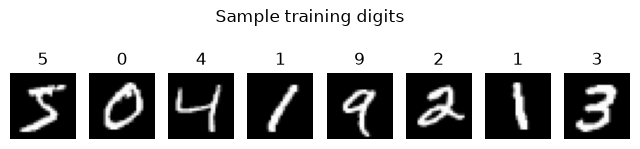

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype('float32')[..., None] / 255.0
x_test = x_test.astype('float32')[..., None] / 255.0
print('Train:', x_train.shape, 'Test:', x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.suptitle('Sample training digits')
plt.show()

## Model


In [5]:
model = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Training


In [6]:
callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_PATH, monitor='val_accuracy', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
]
history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/15
422/422 - 10s - 25ms/step - accuracy: 0.9293 - loss: 0.2370 - val_accuracy: 0.9847 - val_loss: 0.0561 - learning_rate: 0.0010
Epoch 2/15
422/422 - 8s - 18ms/step - accuracy: 0.9786 - loss: 0.0700 - val_accuracy: 0.9880 - val_loss: 0.0400 - learning_rate: 0.0010
Epoch 3/15
422/422 - 8s - 18ms/step - accuracy: 0.9843 - loss: 0.0501 - val_accuracy: 0.9893 - val_loss: 0.0359 - learning_rate: 0.0010
Epoch 4/15
422/422 - 8s - 19ms/step - accuracy: 0.9872 - loss: 0.0405 - val_accuracy: 0.9898 - val_loss: 0.0334 - learning_rate: 0.0010
Epoch 5/15
422/422 - 9s - 21ms/step - accuracy: 0.9895 - loss: 0.0340 - val_accuracy: 0.9913 - val_loss: 0.0302 - learning_rate: 0.0010
Epoch 6/15
422/422 - 10s - 23ms/step - accuracy: 0.9912 - loss: 0.0276 - val_accuracy: 0.9900 - val_loss: 0.0334 - learning_rate: 0.0010
Epoch 7/15
422/422 - 9s - 22ms/step - accuracy: 0.9921 - loss: 0.0244 - val_accuracy: 0.9917 - val_loss: 0.0296 - learning_rate: 0.0010
Epoch 8/15
422/422 - 9s - 22ms/step - accuracy

## Evaluation


Test accuracy: 0.9939   Test loss: 0.0204


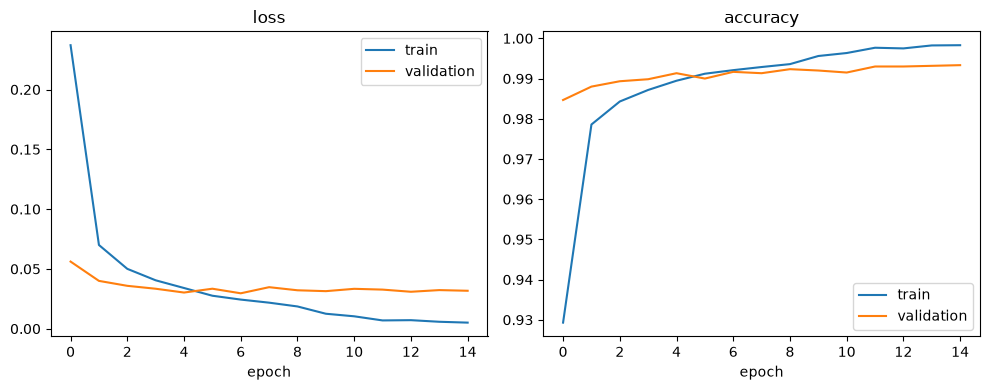

In [7]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test accuracy: {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0     0.9929    0.9980    0.9954       980
           1     0.9965    0.9982    0.9974      1135
           2     0.9913    0.9971    0.9942      1032
           3     0.9931    0.9941    0.9936      1010
           4     0.9949    0.9959    0.9954       982
           5     0.9910    0.9899    0.9905       892
           6     0.9958    0.9906    0.9932       958
           7     0.9922    0.9922    0.9922      1028
           8     0.9959    0.9938    0.9949       974
           9     0.9950    0.9881    0.9915      1009

    accuracy                         0.9939     10000
   macro avg     0.9939    0.9938    0.9938     10000
weighted avg     0.9939    0.9939    0.9939     10000



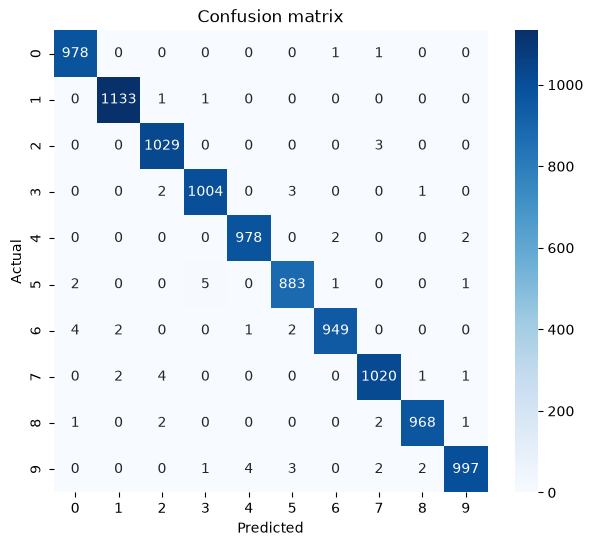

In [8]:
y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

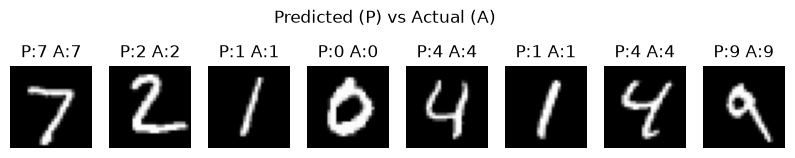

In [9]:
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f'P:{y_pred[i]} A:{y_test[i]}')
    plt.axis('off')
plt.suptitle('Predicted (P) vs Actual (A)')
plt.show()

## Single-image demo & save


Actual: 7   Predicted: 7   Confidence: 1.000


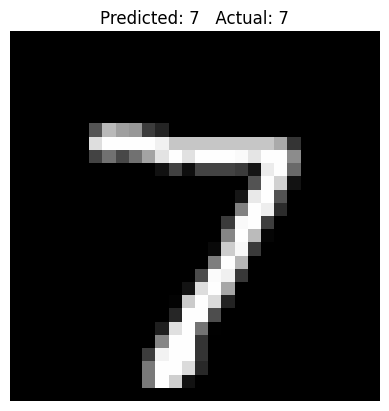

In [ ]:
image_index = 0
test_image = x_test[image_index]
true_label = int(y_test[image_index])
probs = model.predict(np.expand_dims(test_image, 0), verbose=0)[0]
predicted_label = int(probs.argmax())
print(f'Actual: {true_label}   Predicted: {predicted_label}   Confidence: {probs[predicted_label]:.3f}')
plt.imshow(test_image.squeeze(), cmap='gray')
plt.title(f'Predicted: {predicted_label}   Actual: {true_label}')
plt.axis('off')
plt.show()

In [10]:
final_path = os.path.join(OUT_DIR, 'final_model.keras')
model.save(final_path)
pd.DataFrame(history.history).to_csv(os.path.join(OUT_DIR, 'training_log.csv'), index=False)
print('Saved best checkpoint:', CKPT_PATH)
print('Saved final model:', final_path)

Saved best checkpoint: outputs\best_model.keras
Saved final model: outputs\final_model.keras
